<a href="https://colab.research.google.com/github/satyapal2240/satya/blob/main/kannada_cogtrans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CogTrans for Indian Languages: Sentiment Analysis
## kannada

> **Paper:** *CogTrans for Indian Languages: Emotion-Aware Sentiment Analysis Across kannada
> Adapted from: Ahmed et al. (2026), *Information Fusion*, 126(B), 103668.

---
### Instructions
1. Place your CSV files (`kannada_sentiment_dev.csv`, `kannada_sentiment_test.csv`, `kannada_sentiment_train.csv`) in the same directory as this notebook
2. Run all cells in order (Runtime → Run All)

## Section 1 — Environment Setup & Library Installation

### ⚠️ IMPORTANT: Steps for Tomorrow
1. **Open your notebook tomorrow.**
2. **Execute Section 1 (Environment Setup) first.**
3. When a pop-up appears asking you to **"Connect to Google Drive"**, accept it immediately so that all your checkpoints and training runs are backed up in real-time.

In [1]:
# Install required libraries and setup Google Drive directories
!pip install transformers==4.40.0 datasets torch scikit-learn pandas numpy
!pip install indic-nlp-library sentencepiece sacremoses
!pip install matplotlib seaborn tqdm openai

from google.colab import drive
import os

print("\n[INFO] Mounting Google Drive to preserve training progress...")
try:
    drive.mount('/content/drive')
    # Language-specific directory to avoid future ambiguity with other languages
    DRIVE_DIR = '/content/drive/MyDrive/CogTrans_Backup/kannada'
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"[SUCCESS] Progress backup directory is active: {DRIVE_DIR}")
except Exception as e:
    DRIVE_DIR = '.'
    print(f"[WARNING] Google Drive could not be mounted. Progress will be saved locally: {e}")

print('All libraries installed successfully.')

  Using cached transformers-4.40.0-py3-none-any.whl.metadata (137 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached tokenizers-0.19.1.tar.gz (321 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Using cached transformers-4.40.0-py3-none-any.whl (9.0 MB)
Using cached huggingface_hub-0.36.2-py3-none-any.whl (566 kB)
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
Failed to build tokenizers
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)

[INFO] Mounting Google Drive to preserve training progress...
Mounted at /content/

In [2]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
warnings.filterwarnings('ignore')

# Set seeds for reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"}')

Device: cuda
GPU: Tesla T4


## Section 2 — Data Loading

### Local Dataset Upload
Run the cell below to upload your dataset files ( `kannada_data.csv`) directly from your computer.

In [3]:
from google.colab import files
import os

print("Please upload your CSV files now...")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"User uploaded file \"{filename}\" with length {len(uploaded[filename])} bytes")

Please upload your CSV files now...


Saving kannada_sentiment_dev.csv to kannada_sentiment_dev.csv
Saving kannada_sentiment_test.csv to kannada_sentiment_test.csv
Saving kannada_sentiment_train.csv to kannada_sentiment_train.csv
User uploaded file "kannada_sentiment_dev.csv" with length 67203 bytes
User uploaded file "kannada_sentiment_test.csv" with length 75383 bytes
User uploaded file "kannada_sentiment_train.csv" with length 563951 bytes


In [12]:
import os
import pandas as pd

# Updated configuration mapping the uploaded CSV files to Kannada
LANGUAGE_CONFIG = {
    'kannada': {
        'train': 'kannada_sentiment_train.csv',
        'valid': 'kannada_sentiment_dev.csv',
        'test': 'kannada_sentiment_test.csv',
        'backbone': 'google/muril-base-cased',
        'script': 'kannada'
    }
}

# Highly comprehensive label mapping targeting multiple potential formats
LABEL_MAP = {
    'positive': 0, 'negative': 1, 'neutral': 2,
    'not-offensive': 2, 'not_offensive': 2, 'not offensive': 2, 'not_offensive ': 2,
    'offensive_targeted': 1, 'offensive_untargeted': 1,
    'offensive_targeted_insult_group': 1, 'offensive_targeted_insult_individual': 1,
    'off': 1, 'not': 2,
    '0': 0, '1': 1, '2': 2
}

INV_LABEL = {0: 'Positive', 1: 'Negative', 2: 'Neutral'}

def robust_read_csv(path, lang):
    try:
        # Semicolon separated values often found in these shared task datasets
        df = pd.read_csv(path, encoding='utf-8', sep=';', on_bad_lines='skip')
    except Exception as e:
        print(f"[DEBUG] Error reading {path} with semicolon separator: {e}")
        try:
            df = pd.read_csv(path, encoding='utf-8', sep=None, engine='python', on_bad_lines='skip')
        except Exception as e2:
            print(f"[DEBUG] Fallback failed: {e2}")
            df = pd.read_csv(path, encoding='utf-8', sep=',', on_bad_lines='skip')

    # Clean column headers
    df.columns = [str(c).strip().lower() for c in df.columns]
    print(f"[DEBUG] File: {path} | Columns found: {list(df.columns)} | Rows: {len(df)}")

    # Map column headers to text and label
    rename_dict = {}
    for col in df.columns:
        if col in ['text', 'sentence', 'text_clean', 'data', 'tweets', 'tweet', 'comment', 'text ']:
            rename_dict[col] = 'text'
        elif col in ['label', 'category', 'sentiment', 'class', 'offensive', 'status', 'label ']:
            rename_dict[col] = 'label'

    df = df.rename(columns=rename_dict)

    # Positional fallback
    if 'text' not in df.columns or 'label' not in df.columns:
        if df.shape[1] >= 2:
            col1 = df.columns[0]
            col2 = df.columns[1]
            mean_len_1 = df[col1].astype(str).str.len().mean()
            mean_len_2 = df[col2].astype(str).str.len().mean()
            if mean_len_1 > mean_len_2:
                df = df.rename(columns={col1: 'text', col2: 'label'})
            else:
                df = df.rename(columns={col2: 'text', col1: 'label'})
        else:
            df['text'] = ""
            df['label'] = ""

    if 'text' not in df.columns:
        df['text'] = ""
    if 'label' not in df.columns:
        df['label'] = ""

    return df[['text', 'label']]

def load_language_data(lang):
    cfg = LANGUAGE_CONFIG[lang]
    frames = []
    for split in ['train', 'valid', 'test']:
        path = cfg.get(split)
        if path:
            if os.path.exists(path):
                print(f"[INFO] Found split '{split}' at {path}. Reading...")
                df_split = robust_read_csv(path, lang)
                frames.append(df_split)
            else:
                print(f"[WARNING] Split '{split}' file {path} not found in directory.")

    if frames:
        df = pd.concat(frames, ignore_index=True)
        df = df.dropna(subset=['text', 'label'])
        df['text'] = df['text'].astype(str).str.strip()
        df['label'] = df['label'].astype(str).str.strip().str.lower()

        df = df[df['label'].isin(LABEL_MAP.keys())]
        df['label'] = df['label'].map(LABEL_MAP).map(INV_LABEL)

        if len(df) > 0:
            if 'emotion' not in df.columns:
                df['emotion'] = 'unknown'
            print(f'[{lang.upper()}] Successfully loaded {len(df)} samples from your files.')
            return df
        else:
            print(f"[WARNING] Zero matching labels after applying LABEL_MAP in {lang}.")

    print(f'[WARNING] Real data not fully found for {lang} – generating synthetic demo data')
    demo = {
        'text': [f'Sample {lang} text {i}' for i in range(60)],
        'label': (['Positive']*20 + ['Negative']*20 + ['Neutral']*20),
        'emotion': (['joy']*20 + ['anger']*20 + ['no_emotion']*20)
    }
    return pd.DataFrame(demo)

datasets = {'kannada': load_language_data('kannada')}
print('\nAll available datasets mapped and loaded successfully.')

[INFO] Found split 'train' at kannada_sentiment_train.csv. Reading...
[DEBUG] File: kannada_sentiment_train.csv | Columns found: ['sorry sir nim yella video nan nodidini yeno manku badidu nodona hantha download madidde e video nodi delete madidini sir thanks', 'mixed_feelings', 'unnamed: 2'] | Rows: 6134
[INFO] Found split 'valid' at kannada_sentiment_dev.csv. Reading...
[DEBUG] File: kannada_sentiment_dev.csv | Columns found: ['all hands up nand one like', 'unknown_state', 'unnamed: 2'] | Rows: 765
[INFO] Found split 'test' at kannada_sentiment_test.csv. Reading...
[DEBUG] File: kannada_sentiment_test.csv | Columns found: ['heart touching comment nne kelsa aagbeku !!', 'positive', 'unnamed: 2'] | Rows: 767
[KANNADA] Successfully loaded 5001 samples from your files.

All available datasets mapped and loaded successfully.


## Section 3 — Language-Specific Preprocessing

In [13]:
import re, unicodedata
import pandas as pd

# Language-specific stop words adapted for Kannada
STOP_WORDS = {
    'kannada': {'ಮತ್ತು', 'ಆದರೆ', 'ಅಥವಾ', 'ನನ್ನ', 'ಅದು', 'ಈ', 'ಒಂದು', 'ಅವನು', 'ಅವಳು', 'ಅವರು'},
}

def preprocess_text(text, lang):
    if not isinstance(text, str): return ''
    # 1. Unicode normalization
    text = unicodedata.normalize('NFC', text)
    # 2. Lowercase
    text = text.lower()
    # 3. Remove URLs
    text = re.sub(r'http\S+|www\S+', ' URL ', text)
    # 4. Normalize user mentions
    text = re.sub(r'@\w+', '@USER', text)
    # 5. Convert emoji/special symbols to text tokens
    text = re.sub(r'[^\w\s\u0C80-\u0CFF\u0040]', ' EMOJI ', text)
    # 6. Remove excessive whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # 7. Stop word removal
    tokens = text.split()
    sw = STOP_WORDS.get(lang, set())
    tokens = [t for t in tokens if t not in sw]
    return ' '.join(tokens)

# Dynamic definition checks
if 'LABEL_MAP' not in globals():
    LABEL_MAP = {
        'positive': 0, 'negative': 1, 'neutral': 2,
        'not-offensive': 2, 'not_offensive': 2, 'not offensive': 2,
        'offensive_targeted': 1, 'offensive_untargeted': 1,
        'off': 1, 'not': 2,
        '0': 0, '1': 1, '2': 2
    }

def preprocess_dataset(df, lang):
    df = df.copy()
    df['text_clean'] = df['text'].apply(lambda x: preprocess_text(x, lang))
    df['label_id']   = df['label'].astype(str).str.strip().str.lower().map(LABEL_MAP)
    return df

# Fallback safety checks
if 'datasets' not in globals() or not datasets:
    if 'load_language_data' in globals():
        datasets = {'kannada': load_language_data('kannada')}
    else:
        LABEL_MAP_INT = {'positive': 0, 'negative': 1, 'neutral': 2}
        INV_LABEL_STR = {0: 'Positive', 1: 'Negative', 2: 'Neutral'}
        try:
            df_train = pd.read_csv('kannada_sentiment_train.csv', on_bad_lines='skip')
            df_train.columns = [str(c).strip().lower() for c in df_train.columns]
            df_train = df_train.rename(columns={'tweet': 'text', 'label': 'label'})
            df_train = df_train.dropna(subset=['text', 'label'])
            df_train['label'] = df_train['label'].astype(str).str.strip().str.lower().map(LABEL_MAP_INT).map(INV_LABEL_STR)
            df_train['emotion'] = 'unknown'
            datasets = {'kannada': df_train}
        except Exception as e:
            print(f'[WARNING] Local fallback load failed: {e}. Generating synthetic backup.')
            datasets = {'kannada': pd.DataFrame({
                'text': ['ಖುಷಿ!', 'ಬೇಸರ', 'ಉತ್ತಮ'],
                'label': ['Positive', 'Negative', 'Positive'],
                'emotion': ['joy', 'anger', 'joy']
            })}

processed = {lang: preprocess_dataset(df, lang) for lang, df in datasets.items()}
print('Preprocessing complete.')
for lang in processed.keys():
    print(f'\n[{lang.upper()}] Preprocessed Head:')
    display(processed[lang][['text', 'text_clean', 'label', 'label_id']].head(3))

Preprocessing complete.

[KANNADA] Preprocessed Head:


,text,text_clean,label,label_id
0,Bro nin ello hogbutte bedu bro,bro nin ello hogbutte bedu bro,Positive,0
1,ಪೃಥ್ವಿ ಅಂಬರ್ ಏನ್ ಗುರೂ ನೀನು national award win...,ಪೃಥ್ವಿ ಅಂಬರ್ ಏನ್ ಗುರೂ ನೀನು national award winn...,Positive,0
4,Swalpa jasti bildup ayitu annisutte.,swalpa jasti bildup ayitu annisutte EMOJI,Negative,1


## Section 4 — QAM: Quantity Augmentation Module

In [14]:
# ── QAM via synonym replacement (rule-based fallback) ───────────────────
# For full LLM-based augmentation, set USE_LLM = True and supply an OpenAI key.
USE_LLM = False   # Set True if you have an OpenAI API key
OPENAI_KEY = ''   # Set your key here: 'sk-...'
import random
import pandas as pd

def augment_by_deletion(text, drop_prob=0.15):
    """TG-Prompt1 fallback: randomly drop tokens to create a variation."""
    if not isinstance(text, str): return ''
    tokens = text.split()
    if len(tokens) <= 3: return text
    return ' '.join([t for t in tokens if random.random() > drop_prob])

def augment_dataset(df, lang, n_aug=1):
    """Generate n_aug augmented copies per sample."""
    aug_rows = []
    for _, row in df.iterrows():
        for _ in range(n_aug):
            aug_text = augment_by_deletion(row['text_clean'])
            aug_rows.append({
                'text': aug_text, 'text_clean': aug_text,
                'label': row['label'], 'label_id': row['label_id'],
                'emotion': row['emotion'], 'augmented': True
            })
    aug_df = pd.DataFrame(aug_rows)
    df['augmented'] = False
    combined = pd.concat([df, aug_df], ignore_index=True)
    print(f'[{lang.upper()}] Augmented: {len(df)} → {len(combined)} samples')
    return combined

if 'processed' not in globals() or not processed:
    processed = {'kannada': pd.DataFrame({
        'text': ['ಖುಷಿ!', 'ಬೇಸರ', 'ಉತ್ತಮ'],
        'text_clean': ['ಖುಷಿ', 'ಬೇಸರ', 'ಉತ್ತಮ'],
        'label': ['Positive', 'Negative', 'Positive'],
        'label_id': [0, 1, 0],
        'emotion': ['joy', 'anger', 'joy']
    })}

augmented = {}
for lang, df in processed.items():
    # Use more augmentation for low-resource languages like Kannada
    n = 2 if lang in ['kannada'] else 1
    augmented[lang] = augment_dataset(df, lang, n_aug=n)

print('\nQAM augmentation complete.')

[KANNADA] Augmented: 5001 → 15003 samples

QAM augmentation complete.


## Section 5 — ECA: Emotion Cognitive Analysis (OCC Model)

In [15]:
import pandas as pd

# ── Expanded OCC emotion rules supporting kannada and English code-mixed expressions ──────────────────
EMOTION_LEXICON = {
    'kannada': {
        # Native Kannada Script
        'ಖುಷಿ': ('Desirable', 'PECI'),
        'ಪ್ರೀತಿ': ('Desirable', 'PECI'),
        'ಉತ್ತಮ': ('Praiseworthy', 'PECI'),
        'ಅದ್ಭುತ': ('Praiseworthy', 'PECI'),
        'ಧನ್ಯವಾದ': ('Desirable', 'PECI'),
        'ಬೇಸರ': ('Undesirable', 'NECI'),
        'ಕೋಪ': ('Blameworthy', 'NECI'),
        'ಭಯ': ('Undesirable', 'NECI'),
        'ಕೆಟ್ಟ': ('Blameworthy', 'NECI'),
        'ಸುಳ್ಳು': ('Blameworthy', 'NECI'),

        # English & Transliterated/Code-Mixed equivalents
        'happy': ('Desirable', 'PECI'), 'love': ('Desirable', 'PECI'),
        'good': ('Praiseworthy', 'PECI'), 'great': ('Praiseworthy', 'PECI'),
        'nice': ('Praiseworthy', 'PECI'), 'super': ('Praiseworthy', 'PECI'),
        'congrats': ('Desirable', 'PECI'), 'best': ('Praiseworthy', 'PECI'),
        'sad': ('Undesirable', 'NECI'), 'angry': ('Blameworthy', 'NECI'),
        'bad': ('Blameworthy', 'NECI'), 'hate': ('Blameworthy', 'NECI'),
        'worst': ('Blameworthy', 'NECI'), 'fake': ('Blameworthy', 'NECI'),
        'khushi': ('Desirable', 'PECI'), 'preethi': ('Desirable', 'PECI'),
        'sakkath': ('Praiseworthy', 'PECI'), 'chennagide': ('Praiseworthy', 'PECI'),
        'kopha': ('Blameworthy', 'NECI'), 'besara': ('Undesirable', 'NECI')
    },
}

def extract_eca_features(text, lang):
    """Extract PECI/NECI features from text using language lexicon."""
    lexicon = EMOTION_LEXICON.get(lang, {})
    tokens  = text.split()
    peci_score, neci_score = 0, 0
    for token in tokens:
        # Clean token from any trailing punctuation
        clean_token = token.strip('.,!?-~@')
        if clean_token in lexicon:
            _, polarity = lexicon[clean_token]
            if polarity == 'PECI': peci_score += 1
            else:                   neci_score += 1
    total = peci_score + neci_score
    emotion_score = (peci_score - neci_score) / total if total > 0 else 0.0
    dominant = 'PECI' if emotion_score > 0 else ('NECI' if emotion_score < 0 else 'NEUTRAL')
    return {'peci': peci_score, 'neci': neci_score, 'emotion_score': round(emotion_score, 3), 'dominant': dominant}

# Apply ECA to augmented datasets
for lang, df in augmented.items():
    eca_results  = df['text_clean'].apply(lambda t: extract_eca_features(t, lang))
    df['peci']          = eca_results.apply(lambda x: x['peci'])
    df['neci']          = eca_results.apply(lambda x: x['neci'])
    df['emotion_score'] = eca_results.apply(lambda x: x['emotion_score'])
    df['eca_dominant']  = eca_results.apply(lambda x: x['dominant'])

print('ECA features extracted with expanded Kannada-specific lexicon.')
for lang in augmented.keys():
    print(f'\nSample ({lang.upper()}):')
    non_zero_samples = augmented[lang][augmented[lang]['emotion_score'] != 0.0]
    if len(non_zero_samples) > 0:
        display(non_zero_samples[['text_clean', 'peci', 'neci', 'emotion_score', 'eca_dominant']].head(5))
    else:
        display(augmented[lang][['text_clean', 'peci', 'neci', 'emotion_score', 'eca_dominant']].head(5))

ECA features extracted with expanded Kannada-specific lexicon.

Sample (KANNADA):


,text_clean,peci,neci,emotion_score,eca_dominant
4,super guru munduvarisi,1,0,1.0,PECI
5,tik tok super app anna,1,0,1.0,PECI
9,super song 100 days pakka,1,0,1.0,PECI
15,super tippa story,1,0,1.0,PECI
22,o my god wt a acting bro really my eyes are we...,2,0,1.0,PECI


## Section 6 — T-SR: MuRIL/XLM-R Fine-tuning (CogTrans Backbone)

In [16]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import pickle
import os
import math

MAX_LEN   = 128
BATCH_SIZE = 32
LR         = 2e-5

# Fallback to local if DRIVE_DIR was not set during mounting step
if 'DRIVE_DIR' not in globals():
    DRIVE_DIR = '.'

class IndianLangDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], max_length=self.max_len,
            padding='max_length', truncation=True, return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

def train_one_language(lang, df):
    backbone = LANGUAGE_CONFIG[lang]['backbone']

    # Dynamic language subdirectory configuration
    lang_dir = os.path.join(DRIVE_DIR, lang) if not DRIVE_DIR.endswith(lang) else DRIVE_DIR
    os.makedirs(lang_dir, exist_ok=True)

    model_save_path = os.path.join(lang_dir, f'best_model_{lang}.pt')
    results_save_path = os.path.join(lang_dir, f'results_metrics_{lang}.pkl')

    # Check if we already trained this model and saved results in Google Drive
    if os.path.exists(model_save_path) and os.path.exists(results_save_path):
        print(f'\n[INFO] Found existing backup for [{lang.upper()}] in Google Drive. Loading saved progress...')
        try:
            with open(results_save_path, 'rb') as f:
                saved_res = pickle.load(f)
            # Reconstruct model mapping object
            tokenizer = AutoTokenizer.from_pretrained(backbone)
            model = AutoModelForSequenceClassification.from_pretrained(backbone, num_labels=3)
            model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
            model.to(DEVICE)
            saved_res['model'] = model
            saved_res['tokenizer'] = tokenizer
            print(f'  ✓ [{lang.upper()}] LOADED  Accuracy={saved_res["test_acc"]:.4f}  Macro-F1={saved_res["test_f1"]:.4f}')
            return saved_res
        except Exception as e:
            print(f'[WARNING] Failed to load saved progress for {lang}: {e}. Retraining...')

    print(f'\n══ Training [{lang.upper()}] with {backbone} ══')
    tokenizer = AutoTokenizer.from_pretrained(backbone)

    # Split
    X = df['text_clean'].tolist()
    y = df['label_id'].tolist()
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
    X_val,   X_test, y_val,  y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

    # OPTIMIZATION: Cap training size to 15,000 samples to execute well within 2 hours on free GPU
    max_train_samples = 15000
    if len(X_train) > max_train_samples:
        print(f'[INFO] Subsampling training set from {len(X_train)} to {max_train_samples} for rapid execution.')
        X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=max_train_samples, stratify=y_train, random_state=SEED)

    train_ds = IndianLangDataset(X_train, y_train, tokenizer)
    val_ds   = IndianLangDataset(X_val[:2000],   y_val[:2000],   tokenizer)
    test_ds  = IndianLangDataset(X_test[:2000],  y_test[:2000],  tokenizer)

    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
    test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

    # Calculate steps per epoch automatically using: steps = ceil(total / batch_size)
    steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)

    # Dynamic epochs based on steps per epoch condition
    if steps_per_epoch <= 500:
        n_epochs = 10
    elif steps_per_epoch <= 700:
        n_epochs = 8
    else:
        n_epochs = 5

    print(f'[DYNAMIC INFO] Total Training Records: {len(train_ds)} | Batch Size: {BATCH_SIZE} | Steps per Epoch: {steps_per_epoch} | Base Epochs: {n_epochs}')

    model = AutoModelForSequenceClassification.from_pretrained(backbone, num_labels=3)
    model.to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=n_epochs)

    # OPTIMIZATION: Use Automatic Mixed Precision (AMP) for 2x faster GPU throughput
    scaler = torch.cuda.amp.GradScaler()

    best_val_f1 = 0.0
    previous_val_f1 = -1.0
    history = {'train_loss': [], 'val_acc': [], 'val_f1': []}
    gradient_accumulation_steps = 2

    epoch = 0
    current_epochs = n_epochs

    while epoch < current_epochs:
        model.train()
        total_loss = 0
        optimizer.zero_grad()

        for step, batch in enumerate(tqdm(train_dl, desc=f'Epoch {epoch+1}/{current_epochs}', leave=False)):
            input_ids = batch['input_ids'].to(DEVICE)
            attn_mask = batch['attention_mask'].to(DEVICE)
            labels    = batch['label'].to(DEVICE)

            # Execute forward pass under mixed precision
            with torch.cuda.amp.autocast():
                out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
                loss = out.loss / gradient_accumulation_steps

            scaler.scale(loss).backward()

            if (step + 1) % gradient_accumulation_steps == 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            total_loss += loss.item() * gradient_accumulation_steps
        avg_loss = total_loss / len(train_dl)

        # ── Validate ──
        model.eval()
        preds_val, true_val = [], []
        with torch.no_grad():
            for batch in val_dl:
                with torch.cuda.amp.autocast():
                    out = model(
                        input_ids=batch['input_ids'].to(DEVICE),
                        attention_mask=batch['attention_mask'].to(DEVICE)
                    )
                preds_val += out.logits.argmax(-1).cpu().tolist()
                true_val  += batch['label'].tolist()

        val_acc = accuracy_score(true_val, preds_val)
        val_f1  = f1_score(true_val, preds_val, average='macro', zero_division=0)
        history['train_loss'].append(avg_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        scheduler.step()

        is_best = val_f1 > best_val_f1
        if is_best:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), model_save_path)
            torch.save(model.state_dict(), f'best_model_{lang}.pt')

        print(f'  Epoch {epoch+1}: loss={avg_loss:.4f}  val_acc={val_acc:.4f}  val_f1={val_f1:.4f}')

        # Keep adding epochs if the current F1 is higher than the previous epoch's F1
        if epoch == current_epochs - 1:
            if val_f1 > previous_val_f1:
                print(f"  --> [DYNAMIC EXTENSION] Last epoch F1 ({val_f1:.4f}) was greater than previous F1 ({previous_val_f1:.4f}). Appending 1 more epoch.")
                current_epochs += 1

        previous_val_f1 = val_f1
        epoch += 1

    # ── Test ──
    model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
    model.eval()
    preds_test, true_test = [], []
    with torch.no_grad():
        for batch in test_dl:
            with torch.cuda.amp.autocast():
                out = model(
                    input_ids=batch['input_ids'].to(DEVICE),
                    attention_mask=batch['attention_mask'].to(DEVICE)
                )
            preds_test += out.logits.argmax(-1).cpu().tolist()
            true_test  += batch['label'].tolist()

    test_acc = accuracy_score(true_test, preds_test)
    test_f1  = f1_score(true_test, preds_test, average='macro', zero_division=0)
    print(f'\n  ✓ [{lang.upper()}] TEST  Accuracy={test_acc:.4f}  Macro-F1={test_f1:.4f}')

    output_res = {
        'lang': lang, 'test_acc': test_acc, 'test_f1': test_f1,
        'history': history,
        'preds': preds_test, 'true': true_test
    }

    try:
        with open(results_save_path, 'wb') as f:
            pickle.dump(output_res, f)
        print(f"[INFO] Saved results and weights to Drive: {lang_dir}")
    except Exception as e:
        print(f"[WARNING] Failed to write progress file to Drive: {e}")

    output_res['model'] = model
    output_res['tokenizer'] = tokenizer

    return output_res

### Section 6.1 — Copying Trained Progress to Google Drive
Run the cell below to copy your local saved weights and metrics directly to your Google Drive backup directory.

In [17]:
import os
import shutil

# Source paths (local temporary files)
local_model_path = '/content/best_model_kannada.pt'
local_results_dir = '/content/kannada'

# Destination directory in your Google Drive
drive_backup_dir = '/content/drive/MyDrive/CogTrans_Backup/kannada'

print("=== Starting Backup to Google Drive ===")
if os.path.exists('/content/drive'):
    os.makedirs(drive_backup_dir, exist_ok=True)

    # 1. Copy the main best_model_kannada.pt file
    if os.path.exists(local_model_path):
        shutil.copy(local_model_path, os.path.join(drive_backup_dir, 'best_model_kannada.pt'))
        print("✓ Successfully backed up 'best_model_kannada.pt' to your Google Drive!")
    else:
        print("[!] Local 'best_model_kannada.pt' not found in /content. Checking inside subdirectories...")
        fallback_model = '/content/kannada/best_model_kannada.pt'
        if os.path.exists(fallback_model):
            shutil.copy(fallback_model, os.path.join(drive_backup_dir, 'best_model_kannada.pt'))
            print("✓ Successfully backed up 'best_model_kannada.pt' (from subfolder) to your Google Drive!")
        else:
            print("[X] Error: No model weights found locally to copy. Make sure Section 6 has finished training.")

    # 2. Copy the results_metrics_kannada.pkl file
    local_pkl_path = '/content/kannada/results_metrics_kannada.pkl'
    if os.path.exists(local_pkl_path):
        shutil.copy(local_pkl_path, os.path.join(drive_backup_dir, 'results_metrics_kannada.pkl'))
        print("✓ Successfully backed up 'results_metrics_kannada.pkl' to your Google Drive!")
    else:
        print("[!] Evaluation metrics file (.pkl) not found. Run Section 6 first.")

    # 3. Final verification of files in Google Drive
    print("\n=== Verification: Files currently in Google Drive ===")
    print(os.listdir(drive_backup_dir))
else:
    print("[ERROR] Google Drive is not mounted. Please execute Section 1 at the top of the page first.")

=== Starting Backup to Google Drive ===
[!] Local 'best_model_kannada.pt' not found in /content. Checking inside subdirectories...
[X] Error: No model weights found locally to copy. Make sure Section 6 has finished training.
[!] Evaluation metrics file (.pkl) not found. Run Section 6 first.

=== Verification: Files currently in Google Drive ===
[]


In [18]:
import os

drive_backup_dir = '/content/drive/MyDrive/CogTrans_Backup/kannada'

print("=== Google Drive Content Check ===")
if os.path.exists(drive_backup_dir):
    files = os.listdir(drive_backup_dir)
    print(f"Success! Your Google Drive backup folder contains {len(files)} files:\n")
    for idx, f in enumerate(sorted(files), 1):
        size_mb = os.path.getsize(os.path.join(drive_backup_dir, f)) / (1024 * 1024)
        print(f"  {idx}. {f:<30} | Size: {size_mb:.2f} MB")
else:
    print("[ERROR] Backup directory not found on your Google Drive.")

=== Google Drive Content Check ===
Success! Your Google Drive backup folder contains 0 files:



In [20]:
# ── Run training for all kannada configurations with robust NaN filtering ────────────────
results = {}
for lang in LANGUAGE_CONFIG:
    # Filter out any NaN values from the inputs to prevent train_test_split from crashing
    df_clean = augmented[lang].dropna(subset=['text_clean', 'label_id'])
    # Ensure label_id contains only valid integers
    df_clean['label_id'] = df_clean['label_id'].astype(int)

    if len(df_clean) > 0:
        results[lang] = train_one_language(lang, df_clean)
    else:
        print(f"Skipping training for {lang} due to lack of valid cleaned data.")

print('\nkannada language models trained successfully!')


══ Training [KANNADA] with google/muril-base-cased ══
[DYNAMIC INFO] Total Training Records: 10502 | Batch Size: 32 | Steps per Epoch: 329 | Base Epochs: 10


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

  Epoch 1: loss=0.9015  val_acc=0.7260  val_f1=0.4979


  Epoch 2: loss=0.5982  val_acc=0.8665  val_f1=0.8204


...

  Epoch 6: loss=0.1984  val_acc=0.9490  val_f1=0.9374


  Epoch 7: loss=0.1544  val_acc=0.9515  val_f1=0.9409


  Epoch 8: loss=0.1259  val_acc=0.9580  val_f1=0.9496


  Epoch 9: loss=0.1088  val_acc=0.9595  val_f1=0.9515


  Epoch 10: loss=0.0953  val_acc=0.9585  val_f1=0.9497

  ✓ [KANNADA] TEST  Accuracy=0.9555  Macro-F1=0.9473
[INFO] Saved results and weights to Drive: /content/drive/MyDrive/CogTrans_Backup/kannada

kannada language models trained successfully!


In [21]:
from google.colab import drive
import os

# 1. Ensure Google Drive is mounted
try:
    drive.mount('/content/drive')
    print("[SUCCESS] Google Drive is mounted.")
except Exception as e:
    print(f"[ERROR] Failed to mount Drive: {e}")

# 2. Correct the DRIVE_DIR to point to your Drive folder
DRIVE_DIR = '/content/drive/MyDrive/CogTrans_Backup/kannada'
globals()['DRIVE_DIR'] = DRIVE_DIR
print(f"[INFO] Backups path successfully pointed to: {DRIVE_DIR}")

# 3. Verify files are indeed there before running again
if os.path.exists(DRIVE_DIR):
    print(f"[SUCCESS] Backup folder verified. Found files: {os.listdir(DRIVE_DIR)}")
else:
    print("[WARNING] Backup directory still not found on Drive. Please verify the path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[SUCCESS] Google Drive is mounted.
[INFO] Backups path successfully pointed to: /content/drive/MyDrive/CogTrans_Backup/kannada
[SUCCESS] Backup folder verified. Found files: ['best_model_kannada.pt', 'results_metrics_kannada.pkl']


In [22]:
import pickle
import os
import gc
import torch

# --- Clear GPU Memory to Prevent Out Of Memory (OOM) Errors ---
if 'model' in globals():
    del model
if 'optimizer' in globals():
    del optimizer
gc.collect()
torch.cuda.empty_cache()
print("[INFO] GPU Memory cleared successfully!")

# Corrected configuration mapping to point to your uploaded kannada CSV files
LANGUAGE_CONFIG = {
    'kannada': {
        'train': 'kannada_sentiment_train.csv',
        'valid': 'kannada_sentiment_dev.csv',
        'test': 'kannada_sentiment_test.csv',
        'backbone': 'google/muril-base-cased',
        'script': 'kannada'
    }
}

# Force check Google Drive backup directory first
BACKUP_PATH = '/content/drive/MyDrive/CogTrans_Backup/kannada'
if not os.path.exists(BACKUP_PATH):
    BACKUP_PATH = globals().get('DRIVE_DIR', '.')

results = {}
for lang in LANGUAGE_CONFIG:
    # Load augmented dataset from globals if it exists, otherwise skip to load metrics
    if 'augmented' in globals() and lang in augmented:
        df_clean = augmented[lang].dropna(subset=['text_clean', 'label_id'])
        df_clean['label_id'] = df_clean['label_id'].astype(int)
    else:
        df_clean = []

    # Ensure we look inside the verified backup directory
    lang_dir = os.path.join(BACKUP_PATH, lang) if not BACKUP_PATH.endswith(lang) else BACKUP_PATH
    results_save_path = os.path.join(lang_dir, f'results_metrics_{lang}.pkl')

    if os.path.exists(results_save_path):
        print(f"[INFO] Found existing results pickle for {lang.upper()} at {results_save_path}. Loading...")
        with open(results_save_path, 'rb') as f:
            saved_res = pickle.load(f)
        results[lang] = saved_res
        print(f"  ✓ [{lang.upper()}] LOADED Accuracy={saved_res['test_acc']:.4f} Macro-F1={saved_res['test_f1']:.4f}")
    elif len(df_clean) > 0:
        print(f"[INFO] No backup found for {lang.upper()} at {results_save_path}. Training...")
        results[lang] = train_one_language(lang, df_clean)
    else:
        print(f"[WARNING] Could not load backup for {lang.upper()} and no processed dataset is available in runtime. Please run Section 1 to Section 5 first.")

print('\nDone!')

[INFO] GPU Memory cleared successfully!
[INFO] Found existing results pickle for KANNADA at /content/drive/MyDrive/CogTrans_Backup/kannada/results_metrics_kannada.pkl. Loading...
  ✓ [KANNADA] LOADED Accuracy=0.9555 Macro-F1=0.9473

Done!


In [23]:
import os
import shutil

print("=== Step 1: Checking Google Drive Setup ===")
# Safely retrieve DRIVE_DIR from globals or fallback to default
global_drive_dir = globals().get('DRIVE_DIR', '/content/drive/MyDrive/CogTrans_Backup/kannada')

if os.path.exists('/content/drive'):
    os.makedirs(global_drive_dir, exist_ok=True)
    print(f"\n[SUCCESS] Connected to Google Drive!")

    print("\n=== Step 2: Copying saved files from Colab to Google Drive ===")
    local_files = [f for f in os.listdir('.') if f.endswith('.pt') or f.endswith('.pkl') or f.endswith('.zip') or f.endswith('.png')]

    if not local_files:
        print("No local training files (.pt, .pkl, .zip) found in local workspace to back up.")
    else:
        for file_name in local_files:
            dest_path = os.path.join(global_drive_dir, file_name)
            shutil.copy(file_name, dest_path)
            print(f"✓ Copied '{file_name}' to Google Drive ({dest_path})")

    print("\n=== Step 3: Verifying files in your Drive folder ===")
    print(os.listdir(global_drive_dir))
else:
    print("\n[ERROR] Google Drive is not mounted yet.")
    print("Please run Section 1 at the top of the notebook first and authorize Drive access.")

=== Step 1: Checking Google Drive Setup ===

[SUCCESS] Connected to Google Drive!

=== Step 2: Copying saved files from Colab to Google Drive ===
✓ Copied 'best_model_kannada.pt' to Google Drive (/content/drive/MyDrive/CogTrans_Backup/kannada/best_model_kannada.pt)

=== Step 3: Verifying files in your Drive folder ===
['best_model_kannada.pt', 'results_metrics_kannada.pkl']


In [24]:
import os

global_drive_dir = globals().get('DRIVE_DIR', '/content/drive/MyDrive/CogTrans_Backup/kannada')

print("=== Verifying Backup Directory status ===")
if os.path.exists('/content/drive'):
    if os.path.exists(global_drive_dir):
        print(f"\n[SUCCESS] Connected to backup directory: {global_drive_dir}")
        files = os.listdir(global_drive_dir)
        print(f"Found {len(files)} items in backup folder:")
        for idx, file in enumerate(sorted(files), 1):
            size_mb = os.path.getsize(os.path.join(global_drive_dir, file)) / (1024 * 1024)
            print(f"  {idx}. {file:<40} | Size: {size_mb:.2f} MB")
    else:
        print(f"[INFO] Backup directory not created yet. Run Section 1 first to create: {global_drive_dir}")
else:
    print("[ERROR] Google Drive is currently not mounted. Please execute Section 1 at the top.")

=== Verifying Backup Directory status ===

[SUCCESS] Connected to backup directory: /content/drive/MyDrive/CogTrans_Backup/kannada
Found 2 items in backup folder:
  1. best_model_kannada.pt                    | Size: 906.29 MB
  2. results_metrics_kannada.pkl              | Size: 0.01 MB


In [25]:
import os

print("=== Checking Local Directory for Saved Weights ===")
local_files = os.listdir('.')
pt_files = [f for f in local_files if f.endswith('.pt')]
pkl_files = [f for f in local_files if f.endswith('.pkl')]

print(f"Found {len(pt_files)} PyTorch model weight file(s) (.pt):")
for f in sorted(pt_files):
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"  - {f:<30} | Size: {size_mb:.2f} MB")

print(f"\nFound {len(pkl_files)} evaluation metrics file(s) (.pkl):")
for f in sorted(pkl_files):
    print(f"  - {f}")

# Also check inside the local 'kannada' directory fallback
if os.path.exists('./kannada'):
    print("\n=== Checking Local './kannada' Folder ===")
    kannada_files = os.listdir('./kannada')
    for f in sorted(kannada_files):
        size_mb = os.path.getsize(os.path.join('./kannada', f)) / (1024 * 1024)
        print(f"  - kannada/{f:<30} | Size: {size_mb:.2f} MB")

=== Checking Local Directory for Saved Weights ===
Found 1 PyTorch model weight file(s) (.pt):
  - best_model_kannada.pt          | Size: 906.29 MB

Found 0 evaluation metrics file(s) (.pkl):


In [26]:
import os

def search_drive_for_models(start_dir='/content/drive/MyDrive'):
    print(f"Searching for saved model weights in your Google Drive ({start_dir})...")
    found_files = []
    for root, dirs, files in os.walk(start_dir):
        for file in files:
            if 'best_model' in file or 'metrics_kannada' in file or 'cogtrans' in file:
                full_path = os.path.join(root, file)
                found_files.append(full_path)
                print(f"[FOUND] {file} -> {full_path}")

    if not found_files:
         print("No backup files found anywhere in your Google Drive. It is possible they were only saved in the previous temporary local session which has recycled.")
    else:
         print(f"\nSearch complete! Found {len(found_files)} files.")

search_drive_for_models()

Searching for saved model weights in your Google Drive (/content/drive/MyDrive)...
[FOUND] hindi_cogtrans (1).ipynb -> /content/drive/MyDrive/Colab Notebooks/hindi_cogtrans (1).ipynb
[FOUND] hindi_cogtrans4.ipynb -> /content/drive/MyDrive/Colab Notebooks/hindi_cogtrans4.ipynb
[FOUND] hindi_cogtrans5.ipynb -> /content/drive/MyDrive/Colab Notebooks/hindi_cogtrans5.ipynb
[FOUND] hindi_cogtrans 6.ipynb -> /content/drive/MyDrive/Colab Notebooks/hindi_cogtrans 6.ipynb
[FOUND] indian_lang_cogtrans.ipynb -> /content/drive/MyDrive/Colab Notebooks/indian_lang_cogtrans.ipynb
[FOUND] 5 marathi indian_lang_cogtrans.ipynb -> /content/drive/MyDrive/Colab Notebooks/5 marathi indian_lang_cogtrans.ipynb
[FOUND] 1 hindi indian_lang_cogtrans.ipynb -> /content/drive/MyDrive/Colab Notebooks/1 hindi indian_lang_cogtrans.ipynb
[FOUND] 1 hindi indian_lang_cogtrans2.ipynb -> /content/drive/MyDrive/Colab Notebooks/1 hindi indian_lang_cogtrans2.ipynb
[FOUND] hindi_cogtrans.ipynb -> /content/drive/MyDrive/Colab No

## Section 7 — CEIP: Intent Prediction (Simplified)

In [27]:
# Simplified CEIP: maps sentiment + ECA to intent cluster
def predict_intent(sentiment, eca_dominant, lang):
    """Rule-based intent inference (replace with COMET-ATOMIC for production)."""
    intent_map = {
        ('Negative', 'NECI'): 'to express anger or dissatisfaction',
        ('Negative', 'NEUTRAL'): 'to report a concern',
        ('Positive', 'PECI'): 'to express appreciation or support',
        ('Positive', 'NEUTRAL'): 'to share positive experience',
        ('Neutral',  'NEUTRAL'): 'to inform or report factually',
        ('Neutral',  'PECI'): 'to provide encouragement',
        ('Neutral',  'NECI'): 'to raise awareness about an issue',
    }
    return intent_map.get((sentiment, eca_dominant), 'to communicate a message')

# --- SAFE RUNTIME RECOVERY ---
# Reconstruct augmented dataset if the active session memory was cleared
if 'augmented' not in globals() or 'kannada' not in augmented:
    print("[INFO] 'augmented' dataset not found in active session memory. Reconstructing data...")
    try:
        if 'LANGUAGE_CONFIG' not in globals():
            LANGUAGE_CONFIG = {
                'kannada': {
                    'train': 'kannada_sentiment_train.csv',
                    'valid': 'kannada_sentiment_dev.csv',
                    'test': 'kannada_sentiment_test.csv',
                    'backbone': 'google/muril-base-cased',
                    'script': 'kannada'
                }
            }

        if 'load_language_data' not in globals():
            import os
            import pandas as pd
            LABEL_MAP = {
                'positive': 0, 'negative': 1, 'neutral': 2,
                'not-offensive': 2, 'not_offensive': 2, 'not offensive': 2,
                'offensive_targeted': 1, 'offensive_untargeted': 1,
                'off': 1, 'not': 2,
                '0': 0, '1': 1, '2': 2
            }
            INV_LABEL = {0: 'Positive', 1: 'Negative', 2: 'Neutral'}

            def robust_read_csv(path, lang):
                try:
                    df = pd.read_csv(path, encoding='utf-8', sep=';', on_bad_lines='skip')
                except Exception:
                    df = pd.read_csv(path, encoding='utf-8', sep=None, engine='python', on_bad_lines='skip')
                df.columns = [str(c).strip().lower() for c in df.columns]
                rename_dict = {}
                for col in df.columns:
                    if col in ['text', 'sentence', 'text_clean', 'data', 'tweets', 'tweet', 'comment']:
                        rename_dict[col] = 'text'
                    elif col in ['label', 'category', 'sentiment', 'class', 'status']:
                        rename_dict[col] = 'label'
                df = df.rename(columns=rename_dict)
                if 'text' not in df.columns or 'label' not in df.columns:
                    if df.shape[1] >= 2:
                        df = df.rename(columns={df.columns[0]: 'text', df.columns[1]: 'label'})
                return df[['text', 'label']]

            def load_language_data(lang):
                cfg = LANGUAGE_CONFIG[lang]
                frames = []
                for split in ['train', 'valid', 'test']:
                    path = cfg.get(split)
                    if path and os.path.exists(path):
                        frames.append(robust_read_csv(path, lang))
                if frames:
                    df = pd.concat(frames, ignore_index=True).dropna(subset=['text', 'label'])
                    df['text'] = df['text'].astype(str).str.strip()
                    df['label'] = df['label'].astype(str).str.strip().str.lower()
                    df = df[df['label'].isin(LABEL_MAP.keys())]
                    df['label'] = df['label'].map(LABEL_MAP).map(INV_LABEL)
                    df['emotion'] = 'unknown'
                    return df
                raise FileNotFoundError("Dataset split files not found.")

        if 'preprocess_dataset' not in globals():
            import re, unicodedata
            # Correct Kannada native stop words definition for safety
            STOP_WORDS = {'kannada': {'ಮತ್ತು', 'ಆದರೆ', 'ಅಥವಾ', 'ನನ್ನ', 'ಅದು', 'ಈ', 'ಒಂದು', 'ಅವನು', 'ಅವಳು', 'ಅವರು'}}
            def preprocess_text(text, lang):
                text = unicodedata.normalize('NFC', str(text)).lower()
                text = re.sub(r'http\S+|www\S+', ' URL ', text)
                text = re.sub(r'@\w+', '@USER', text)
                text = re.sub(r'[^\w\s\u0C80-\u0CFF\u0040]', ' EMOJI ', text)
                text = re.sub(r'\s+', ' ', text).strip()
                return ' '.join([t for t in text.split() if t not in STOP_WORDS.get(lang, set())])
            def preprocess_dataset(df, lang):
                df = df.copy()
                df['text_clean'] = df['text'].apply(lambda x: preprocess_text(x, lang))
                df['label_id'] = df['label'].map({'Positive': 0, 'Negative': 1, 'Neutral': 2})
                return df

        if 'augment_dataset' not in globals():
            import random
            def augment_by_deletion(text, drop_prob=0.15):
                tokens = str(text).split()
                if len(tokens) <= 3: return text
                return ' '.join([t for t in tokens if random.random() > drop_prob])
            def augment_dataset(df, lang, n_aug=1):
                aug_rows = []
                for _, row in df.iterrows():
                    for _ in range(n_aug):
                        aug_text = augment_by_deletion(row['text_clean'])
                        aug_rows.append({
                            'text': aug_text, 'text_clean': aug_text,
                            'label': row['label'], 'label_id': row['label_id'],
                            'emotion': row['emotion'], 'augmented': True
                        })
                df['augmented'] = False
                return pd.concat([df, pd.DataFrame(aug_rows)], ignore_index=True)

        if 'extract_eca_features' not in globals():
            def extract_eca_features(text, lang):
                from eca_module import EMOTION_LEXICON # or fallback local map
                lexicon = {
                    'happy': ('Desirable', 'PECI'), 'sad': ('Undesirable', 'NECI'),
                    'ಖುಷಿ': ('Desirable', 'PECI'), 'ಬೇಸರ': ('Undesirable', 'NECI')
                }
                tokens = str(text).split()
                peci, neci = 0, 0
                for token in tokens:
                    clean_token = token.strip('.,!?-~@')
                    if clean_token in lexicon:
                        if lexicon[clean_token][1] == 'PECI': peci += 1
                        else: neci += 1
                total = peci + neci
                score = (peci - neci) / total if total > 0 else 0.0
                dominant = 'PECI' if score > 0 else ('NECI' if score < 0 else 'NEUTRAL')
                return {'peci': peci, 'neci': neci, 'emotion_score': round(score, 3), 'dominant': dominant}

        # Process execution
        datasets = {lang: load_language_data(lang) for lang in LANGUAGE_CONFIG}
        processed = {lang: preprocess_dataset(df, lang) for lang, df in datasets.items()}
        augmented = {}
        for lang, df in processed.items():
            n = 2 if lang in ['kannada'] else 1
            augmented[lang] = augment_dataset(df, lang, n_aug=n)

            eca_results  = augmented[lang]['text_clean'].apply(lambda t: extract_eca_features(t, lang))
            augmented[lang]['peci']          = eca_results.apply(lambda x: x['peci'])
            augmented[lang]['neci']          = eca_results.apply(lambda x: x['neci'])
            augmented[lang]['emotion_score'] = eca_results.apply(lambda x: x['emotion_score'])
            augmented[lang]['eca_dominant']  = eca_results.apply(lambda x: x['dominant'])
        print("[SUCCESS] Augmented dataset successfully reconstructed in runtime!")
    except Exception as e:
        print(f"[ERROR] Could not automatically reconstruct datasets: {e}")
        print("Please run Section 1 through Section 5 first.")

# Dynamically fetch the first available language from your loaded data
if 'augmented' in globals() and len(augmented) > 0:
    active_lang = 'kannada'
    print(f"[INFO] Displaying intent prediction demo for loaded language: {active_lang.upper()}\n")

    sample = augmented[active_lang].sample(5, random_state=42)
    for _, row in sample.iterrows():
        intent = predict_intent(row['label'], row['eca_dominant'], active_lang)
        print(f"Text    : {row['text_clean'][:60]}...")
        print(f"Sentiment: {row['label']}  |  ECA: {row['eca_dominant']}  |  Intent: {intent}")
        print()
else:
    print("[WARNING] Please run Section 1 through Section 5 first to enable intent prediction.")

[INFO] Displaying intent prediction demo for loaded language: KANNADA

Text    : adru namboru thumba jana edare sir...
Sentiment: Positive  |  ECA: NEUTRAL  |  Intent: to share positive experience

Text    : ಕನ್ನಡದಲ್ಲೆ ಹೆಚ್ಚಾಗಿ ಮಾತನಾಡಿದ್ದಕ್ಕೆ ಧನ್ಯವಾದಗಳು EMOJI EMOJI EM...
Sentiment: Positive  |  ECA: PECI  |  Intent: to express appreciation or support

Text    : ಚಂದನ್ ಶೆಟ್ಟಿ ಟ್ರೊಲ್ ವಿಡಿಯೋ ನೀವು ನೋಡಿ ಗ್ಯಾರಂಟಿ...
Sentiment: Positive  |  ECA: NEUTRAL  |  Intent: to share positive experience

Text    : ಚಂದನ್ ವಿಡಿಯೋ ನೀವು ನೋಡಿ ಇದ್ರೆ ನಾವ್ ಗ್ಯಾರಂಟಿ...
Sentiment: Positive  |  ECA: NEUTRAL  |  Intent: to share positive experience

Text    : ಅದ್ಭುತವಾದ ಸಿನಿಮಾ EMOJI ನಾನು ಇತ್ತೀಚೆಗೆ ನೋಡಿದ ಎಲ್ಲ ಕನ್ನಡ ಸಿನಿಮ...
Sentiment: Negative  |  ECA: NEUTRAL  |  Intent: to report a concern



## Section 8 — Evaluation: Accuracy, Macro-F1, Classification Report

In [28]:
import pandas as pd
from sklearn.metrics import classification_report

print('=' * 70)
print(f'  {"LANGUAGE":<12}  {"ACCURACY":>10}  {"MACRO-F1":>10}')
print('=' * 70)

summary_rows = []
for lang, res in results.items():
    print(f'  {lang.upper():<12}  {res["test_acc"]*100:>9.2f}%  {res["test_f1"]*100:>9.2f}%')
    summary_rows.append({
        'Language': lang.title(),
        'Accuracy (%)': round(res['test_acc']*100, 2),
        'Macro-F1 (%)': round(res['test_f1']*100, 2)
    })

print('=' * 70)

summary_df = pd.DataFrame(summary_rows)
print('\nDetailed Classification Reports:')
for lang, res in results.items():
    print(f'\n── {lang.upper()} ──')
    target_names = [INV_LABEL[i] for i in range(3)]
    print(classification_report(res['true'], res['preds'], labels=[0, 1, 2], target_names=target_names, zero_division=0))

  LANGUAGE        ACCURACY    MACRO-F1
  KANNADA           95.55%      94.73%

Detailed Classification Reports:

── KANNADA ──
              precision    recall  f1-score   support

    Positive       0.97      0.97      0.97      1396
    Negative       0.92      0.93      0.93       604
     Neutral       0.00      0.00      0.00         0

    accuracy                           0.96      2000
   macro avg       0.63      0.63      0.63      2000
weighted avg       0.96      0.96      0.96      2000



## Section 8.1 — Baseline Training for kannada
Here we train four popular baseline pre-trained language models (**mBERT**, **IndicBERT**, **XLM-R**, and **MuRIL**) for 3 epochs each on the kannada dataset to compare directly against CogTrans.

In [29]:
import os
import pickle
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Define seed locally if missing from active runtime
SEED = 42

# ── Preparation: Split Data ──
active_lang = 'kannada'
print(f"[INFO] Preparing dataset splits for {active_lang.upper()} Baselines...")

if 'DRIVE_DIR' not in globals():
    DRIVE_DIR = '/content/drive/MyDrive/CogTrans_Backup/kannada'

# Filter out NaN values from the active dataset
lang_df = augmented[active_lang].dropna(subset=['text_clean', 'label_id'])
lang_df['label_id'] = lang_df['label_id'].astype(int)

# Split active language data
X_lang = lang_df['text_clean'].tolist()
y_lang = lang_df['label_id'].tolist()

X_train_k, X_tmp_k, y_train_k, y_tmp_k = train_test_split(X_lang, y_lang, test_size=0.30, stratify=y_lang, random_state=SEED)
# Cap the training validation splits as done during main model training for speed
max_train_samples = 15000
if len(X_train_k) > max_train_samples:
    print(f"[INFO] Capping baseline training samples from {len(X_train_k)} to {max_train_samples} for rapid execution.")
    X_train_k, _, y_train_k, _ = train_test_split(X_train_k, y_train_k, train_size=max_train_samples, stratify=y_train_k, random_state=SEED)

X_val_k,   X_test_k, y_val_k,  y_test_k = train_test_split(X_tmp_k, y_tmp_k, test_size=0.50, stratify=y_tmp_k, random_state=SEED)

# Cap validation and test to 2,000 each for speed
X_val_k = X_val_k[:2000]
y_val_k = y_val_k[:2000]
X_test_k = X_test_k[:2000]
y_test_k = y_test_k[:2000]

# Dictionary to accumulate overall performance across cells
if 'baseline_results' not in globals():
    baseline_results = {}

print("✔ Dataset split completed successfully. Ready to train baseline models with fast execution!")

[INFO] Preparing dataset splits for KANNADA Baselines...
✔ Dataset split completed successfully. Ready to train baseline models with fast execution!


In [30]:
# ── Training Baseline: mBERT ──
name = 'mBERT'
model_path = 'bert-base-multilingual-cased'

# Unique Google Drive path for mBERT
model_save_dir = os.path.join(os.path.dirname(DRIVE_DIR), 'kannada-mbert')
os.makedirs(model_save_dir, exist_ok=True)

model_save_path = os.path.join(model_save_dir, f'best_baseline_{name}.pt')
metrics_save_path = os.path.join(model_save_dir, f'metrics_baseline_{name}.pkl')

if os.path.exists(model_save_path) and os.path.exists(metrics_save_path):
    print(f"[INFO] Found existing backup for baseline [{name}] in Google Drive. Skipping training...")
    with open(metrics_save_path, 'rb') as f:
        baseline_results[name] = pickle.load(f)
    print(f"  ✓ [{name}] LOADED  Accuracy={baseline_results[name]['accuracy']:.4f}  Macro-F1={baseline_results[name]['f1']:.4f}")
else:
    print(f"\n══ Training Baseline [{name}] (Saving to: {model_save_dir}) ══")
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        train_ds = IndianLangDataset(X_train_k, y_train_k, tokenizer)
        val_ds   = IndianLangDataset(X_val_k,   y_val_k,   tokenizer)
        test_ds  = IndianLangDataset(X_test_k,  y_test_k,  tokenizer)

        train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
        test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

        # Dynamically calculate steps per epoch using: steps = ceil(total / batch_size)
        steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)

        # Dynamic epochs based on steps per epoch condition
        if steps_per_epoch <= 500:
            current_epochs = 10
        elif steps_per_epoch <= 700:
            current_epochs = 8
        else:
            current_epochs = 5

        print(f'[DYNAMIC INFO] {name} - Total Training Records: {len(train_ds)} | Batch Size: {BATCH_SIZE} | Steps per Epoch: {steps_per_epoch} | Base Epochs: {current_epochs}')

        model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=3)
        model.to(DEVICE)

        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        best_val_f1 = 0.0
        previous_val_f1 = -1.0

        epoch = 0

        while epoch < current_epochs:
            model.train()
            total_loss = 0
            for batch in tqdm(train_dl, desc=f'Epoch {epoch+1}/{current_epochs} (Training)', leave=False):
                input_ids = batch['input_ids'].to(DEVICE)
                attn_mask = batch['attention_mask'].to(DEVICE)
                labels    = batch['label'].to(DEVICE)
                optimizer.zero_grad()
                out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
                loss = out.loss
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_dl)

            # Evaluate at end of epoch
            model.eval()
            preds_val, true_val = [], []
            with torch.no_grad():
                for batch in val_dl:
                    out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                    preds_val += out.logits.argmax(-1).cpu().tolist()
                    true_val  += batch['label'].tolist()

            val_acc = accuracy_score(true_val, preds_val)
            val_f1 = f1_score(true_val, preds_val, average='macro', zero_division=0)
            print(f"  Epoch {epoch+1}/{current_epochs} Done | Loss: {avg_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro-F1: {val_f1:.4f}")

            is_best = val_f1 >= best_val_f1
            if is_best:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), model_save_path)
                torch.save(model.state_dict(), f'best_baseline_{name}.pt')
                print(f"  --> [SAVED] New best validation F1 score: {val_f1:.4f}")

            # Keep adding epochs if the current F1 is higher than the previous epoch's F1
            if epoch == current_epochs - 1:
                if val_f1 > previous_val_f1:
                    print(f"  --> [DYNAMIC EXTENSION] Last epoch F1 ({val_f1:.4f}) was greater than previous F1 ({previous_val_f1:.4f}). Extending 1 more epoch for [{name}] to recover/improve.")
                    current_epochs += 1

            previous_val_f1 = val_f1
            epoch += 1

        model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
        model.eval()
        preds_test, true_test = [], []
        with torch.no_grad():
            for batch in test_dl:
                out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                preds_test += out.logits.argmax(-1).cpu().tolist()
                true_test  += batch['label'].tolist()

        test_acc = accuracy_score(true_test, preds_test)
        test_f1  = f1_score(true_test, preds_test, average='macro', zero_division=0)

        res_dict = {'accuracy': test_acc, 'f1': test_f1}
        baseline_results[name] = res_dict

        with open(metrics_save_path, 'wb') as f:
            pickle.dump(res_dict, f)

        print(f'  ✓ [{name}] TEST COMPLETE  Accuracy={test_acc:.4f}  Macro-F1={test_f1:.4f}')
    except Exception as e:
        print(f'Error training {name}: {e}')


══ Training Baseline [mBERT] (Saving to: /content/drive/MyDrive/CogTrans_Backup/kannada-mbert) ══


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

...

  Epoch 7/10 Done | Loss: 0.0282 | Val Acc: 0.9690 | Val Macro-F1: 0.9625
  --> [SAVED] New best validation F1 score: 0.9625


  Epoch 8/10 Done | Loss: 0.0226 | Val Acc: 0.9655 | Val Macro-F1: 0.9579


  Epoch 9/10 Done | Loss: 0.0204 | Val Acc: 0.9610 | Val Macro-F1: 0.9527


  Epoch 10/10 Done | Loss: 0.0188 | Val Acc: 0.9690 | Val Macro-F1: 0.9630
  --> [SAVED] New best validation F1 score: 0.9630
  --> [DYNAMIC EXTENSION] Last epoch F1 (0.9630) was greater than previous F1 (0.9527). Extending 1 more epoch for [mBERT] to recover/improve.


  Epoch 11/11 Done | Loss: 0.0165 | Val Acc: 0.9660 | Val Macro-F1: 0.9599
  ✓ [mBERT] TEST COMPLETE  Accuracy=0.9655  Macro-F1=0.9591


In [31]:
import os

mbert_drive_dir = '/content/drive/MyDrive/CogTrans_Backup/kannada-mbert'

print("=== mBERT Google Drive Backup Verification ===")
if os.path.exists(mbert_drive_dir):
    files = os.listdir(mbert_drive_dir)
    print(f"[SUCCESS] Directory exists in your Google Drive with {len(files)} file(s):")
    for idx, f in enumerate(sorted(files), 1):
        size_mb = os.path.getsize(os.path.join(mbert_drive_dir, f)) / (1024 * 1024)
        print(f"  {idx}. {f:<30} | Size: {size_mb:.2f} MB")
else:
    print(f"[WARNING] Could not find the directory: {mbert_drive_dir}")
    print("Please make sure Google Drive is mounted in Section 1.")

=== mBERT Google Drive Backup Verification ===
[SUCCESS] Directory exists in your Google Drive with 2 file(s):
  1. best_baseline_mBERT.pt         | Size: 678.55 MB
  2. metrics_baseline_mBERT.pkl     | Size: 0.00 MB


In [32]:
# ── Training Baseline: XLM-R ──
name = 'XLM-R'
model_path = 'xlm-roberta-base'

# Unique Google Drive path for XLM-R
model_save_dir = os.path.join(os.path.dirname(DRIVE_DIR), 'kannada-xlmr')
os.makedirs(model_save_dir, exist_ok=True)

model_save_path = os.path.join(model_save_dir, f'best_baseline_{name}.pt')
metrics_save_path = os.path.join(model_save_dir, f'metrics_baseline_{name}.pkl')

if os.path.exists(model_save_path) and os.path.exists(metrics_save_path):
    print(f"[INFO] Found existing backup for baseline [{name}] in Google Drive. Skipping training...")
    with open(metrics_save_path, 'rb') as f:
        baseline_results[name] = pickle.load(f)
    print(f"  ✓ [{name}] LOADED  Accuracy={baseline_results[name]['accuracy']:.4f}  Macro-F1={baseline_results[name]['f1']:.4f}")
else:
    print(f"\n══ Training Baseline [{name}] (Saving to: {model_save_dir}) ══")
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        train_ds = IndianLangDataset(X_train_k, y_train_k, tokenizer)
        val_ds   = IndianLangDataset(X_val_k,   y_val_k,   tokenizer)
        test_ds  = IndianLangDataset(X_test_k,  y_test_k,  tokenizer)

        train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
        test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

        # Dynamically calculate steps per epoch using: steps = ceil(total / batch_size)
        steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)

        # Dynamic epochs based on steps per epoch condition
        if steps_per_epoch <= 500:
            current_epochs = 10
        elif steps_per_epoch <= 700:
            current_epochs = 8
        else:
            current_epochs = 5

        print(f'[DYNAMIC INFO] {name} - Total Training Records: {len(train_ds)} | Batch Size: {BATCH_SIZE} | Steps per Epoch: {steps_per_epoch} | Base Epochs: {current_epochs}')

        model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=3)
        model.to(DEVICE)

        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        best_val_f1 = 0.0
        previous_val_f1 = -1.0

        epoch = 0

        while epoch < current_epochs:
            model.train()
            total_loss = 0
            for batch in tqdm(train_dl, desc=f'Epoch {epoch+1}/{current_epochs} (Training)', leave=False):
                input_ids = batch['input_ids'].to(DEVICE)
                attn_mask = batch['attention_mask'].to(DEVICE)
                labels    = batch['label'].to(DEVICE)
                optimizer.zero_grad()
                out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
                loss = out.loss
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_dl)

            # Evaluate at end of epoch
            model.eval()
            preds_val, true_val = [], []
            with torch.no_grad():
                for batch in val_dl:
                    out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                    preds_val += out.logits.argmax(-1).cpu().tolist()
                    true_val  += batch['label'].tolist()

            val_acc = accuracy_score(true_val, preds_val)
            val_f1 = f1_score(true_val, preds_val, average='macro', zero_division=0)
            print(f"  Epoch {epoch+1}/{current_epochs} Done | Loss: {avg_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro-F1: {val_f1:.4f}")

            is_best = val_f1 >= best_val_f1
            if is_best:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), model_save_path)
                torch.save(model.state_dict(), f'best_baseline_{name}.pt')
                print(f"  --> [SAVED] New best validation F1 score: {val_f1:.4f}")

            # Keep adding epochs if the current F1 is higher than the previous epoch's F1
            if epoch == current_epochs - 1:
                if val_f1 > previous_val_f1:
                    print(f"  --> [DYNAMIC EXTENSION] Last epoch F1 ({val_f1:.4f}) was greater than previous F1 ({previous_val_f1:.4f}). Extending 1 more epoch for [{name}] to recover/improve.")
                    current_epochs += 1

            previous_val_f1 = val_f1
            epoch += 1

        model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
        model.eval()
        preds_test, true_test = [], []
        with torch.no_grad():
            for batch in test_dl:
                out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                preds_test += out.logits.argmax(-1).cpu().tolist()
                true_test  += batch['label'].tolist()

        test_acc = accuracy_score(true_test, preds_test)
        test_f1  = f1_score(true_test, preds_test, average='macro', zero_division=0)

        res_dict = {'accuracy': test_acc, 'f1': test_f1}
        baseline_results[name] = res_dict

        with open(metrics_save_path, 'wb') as f:
            pickle.dump(res_dict, f)

        print(f'  ✓ [{name}] TEST COMPLETE  Accuracy={test_acc:.4f}  Macro-F1={test_f1:.4f}')
    except Exception as e:
        print(f'Error training {name}: {e}')


══ Training Baseline [XLM-R] (Saving to: /content/drive/MyDrive/CogTrans_Backup/kannada-xlmr) ══
[DYNAMIC INFO] XLM-R - Total Training Records: 10502 | Batch Size: 32 | Steps per Epoch: 329 | Base Epochs: 10


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

  Epoch 6/10 Done | Loss: 0.2321 | Val Acc: 0.9025 | Val Macro-F1: 0.8779
  --> [SAVED] New best validation F1 score: 0.8779


  Epoch 7/10 Done | Loss: 0.2585 | Val Acc: 0.8855 | Val Macro-F1: 0.8454


  Epoch 8/10 Done | Loss: 0.2431 | Val Acc: 0.8915 | Val Macro-F1: 0.8569


  Epoch 9/10 Done | Loss: 0.2245 | Val Acc: 0.8940 | Val Macro-F1: 0.8601


  Epoch 10/10 Done | Loss: 0.2193 | Val Acc: 0.8915 | Val Macro-F1: 0.8539
  ✓ [XLM-R] TEST COMPLETE  Accuracy=0.9075  Macro-F1=0.8856


In [33]:
# ── Training Baseline: MuRIL ──
name = 'MuRIL'
model_path = 'google/muril-base-cased'

# Unique Google Drive path for MuRIL
model_save_dir = os.path.join(os.path.dirname(DRIVE_DIR), 'kannada-muril')
os.makedirs(model_save_dir, exist_ok=True)

model_save_path = os.path.join(model_save_dir, f'best_baseline_{name}.pt')
metrics_save_path = os.path.join(model_save_dir, f'metrics_baseline_{name}.pkl')

if os.path.exists(model_save_path) and os.path.exists(metrics_save_path):
    print(f"[INFO] Found existing backup for baseline [{name}] in Google Drive. Skipping training...")
    with open(metrics_save_path, 'rb') as f:
        baseline_results[name] = pickle.load(f)
    print(f"  ✓ [{name}] LOADED  Accuracy={baseline_results[name]['accuracy']:.4f}  Macro-F1={baseline_results[name]['f1']:.4f}")
else:
    print(f"\n══ Training Baseline [{name}] (Saving to: {model_save_dir}) ══")
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        train_ds = IndianLangDataset(X_train_k, y_train_k, tokenizer)
        val_ds   = IndianLangDataset(X_val_k,   y_val_k,   tokenizer)
        test_ds  = IndianLangDataset(X_test_k,  y_test_k,  tokenizer)

        train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
        test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

        model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=3)
        model.to(DEVICE)

        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        best_val_f1 = 0.0

        for epoch in range(3):
            model.train()
            total_loss = 0
            for batch in tqdm(train_dl, desc=f'Epoch {epoch+1}/3 (Training)', leave=False):
                input_ids = batch['input_ids'].to(DEVICE)
                attn_mask = batch['attention_mask'].to(DEVICE)
                labels    = batch['label'].to(DEVICE)
                optimizer.zero_grad()
                out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
                loss = out.loss
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_dl)

            # Evaluate at end of epoch
            model.eval()
            preds_val, true_val = [], []
            with torch.no_grad():
                for batch in val_dl:
                    out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                    preds_val += out.logits.argmax(-1).cpu().tolist()
                    true_val  += batch['label'].tolist()

            val_acc = accuracy_score(true_val, preds_val)
            val_f1 = f1_score(true_val, preds_val, average='macro', zero_division=0)
            print(f"  Epoch {epoch+1}/3 Done | Loss: {avg_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro-F1: {val_f1:.4f}")

            if val_f1 >= best_val_f1:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), model_save_path)
                torch.save(model.state_dict(), f'best_baseline_{name}.pt')
                print(f"  --> [SAVED] New best validation F1 score: {val_f1:.4f}")

        model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
        model.eval()
        preds_test, true_test = [], []
        with torch.no_grad():
            for batch in test_dl:
                out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                preds_test += out.logits.argmax(-1).cpu().tolist()
                true_test  += batch['label'].tolist()

        test_acc = accuracy_score(true_test, preds_test)
        test_f1  = f1_score(true_test, preds_test, average='macro', zero_division=0)

        res_dict = {'accuracy': test_acc, 'f1': test_f1}
        baseline_results[name] = res_dict

        with open(metrics_save_path, 'wb') as f:
            pickle.dump(res_dict, f)

        print(f'  ✓ [{name}] TEST COMPLETE  Accuracy={test_acc:.4f}  Macro-F1={test_f1:.4f}')
    except Exception as e:
        print(f'Error training {name}: {e}')


══ Training Baseline [MuRIL] (Saving to: /content/drive/MyDrive/CogTrans_Backup/kannada-muril) ══


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

  Epoch 1/3 Done | Loss: 0.7886 | Val Acc: 0.7030 | Val Macro-F1: 0.4128
  --> [SAVED] New best validation F1 score: 0.4128


  Epoch 2/3 Done | Loss: 0.4989 | Val Acc: 0.8545 | Val Macro-F1: 0.8191
  --> [SAVED] New best validation F1 score: 0.8191


  Epoch 3/3 Done | Loss: 0.2967 | Val Acc: 0.8975 | Val Macro-F1: 0.8680
  --> [SAVED] New best validation F1 score: 0.8680
  ✓ [MuRIL] TEST COMPLETE  Accuracy=0.8970  Macro-F1=0.8681


In [34]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
import torch
import os
import pickle
import math
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Local parameters setup for baseline standalone safety
MAX_LEN = 128
BATCH_SIZE = 16
LR = 2e-5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42

class IndianLangDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], max_length=self.max_len,
            padding='max_length', truncation=True, return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

name = 'MuRIL'
model_path = 'google/muril-base-cased'

# Unique Google Drive path for MuRIL
model_save_dir = os.path.join(os.path.dirname(DRIVE_DIR), 'kannada-muril')
os.makedirs(model_save_dir, exist_ok=True)

model_save_path = os.path.join(model_save_dir, f'best_baseline_{name}.pt')
metrics_save_path = os.path.join(model_save_dir, f'metrics_baseline_{name}.pkl')

if os.path.exists(model_save_path) and os.path.exists(metrics_save_path):
    print(f"[INFO] Found existing backup for baseline [{name}] in Google Drive. Skipping training...")
    with open(metrics_save_path, 'rb') as f:
        baseline_results[name] = pickle.load(f)
    print(f"  ✓ [{name}] LOADED  Accuracy={baseline_results[name]['accuracy']:.4f}  Macro-F1={baseline_results[name]['f1']:.4f}")
else:
    print(f"\n══ Training Baseline [{name}] (Saving to: {model_save_dir}) ══")
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        train_ds = IndianLangDataset(X_train_k, y_train_k, tokenizer)
        val_ds   = IndianLangDataset(X_val_k,   y_val_k,   tokenizer)
        test_ds  = IndianLangDataset(X_test_k,  y_test_k,  tokenizer)

        train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
        test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

        # Dynamically calculate steps per epoch using: steps = ceil(total / batch_size)
        steps_per_epoch = math.ceil(len(train_ds) / BATCH_SIZE)
        print(f'[DYNAMIC INFO] {name} - Total Training Records: {len(train_ds)} | Batch Size: {BATCH_SIZE} | Steps per Epoch: {steps_per_epoch}')

        model = AutoModelForSequenceClassification.from_pretrained(model_path, num_labels=3)
        model.to(DEVICE)

        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        best_val_f1 = 0.0

        epoch = 0
        current_epochs = 3

        while epoch < current_epochs:
            model.train()
            total_loss = 0
            for batch in tqdm(train_dl, desc=f'Epoch {epoch+1}/{current_epochs} (Training)', leave=False):
                input_ids = batch['input_ids'].to(DEVICE)
                attn_mask = batch['attention_mask'].to(DEVICE)
                labels    = batch['label'].to(DEVICE)
                optimizer.zero_grad()
                out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
                loss = out.loss
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_dl)

            # Evaluate at end of epoch
            model.eval()
            preds_val, true_val = [], []
            with torch.no_grad():
                for batch in val_dl:
                    out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                    preds_val += out.logits.argmax(-1).cpu().tolist()
                    true_val  += batch['label'].tolist()

            val_acc = accuracy_score(true_val, preds_val)
            val_f1 = f1_score(true_val, preds_val, average='macro', zero_division=0)
            print(f"  Epoch {epoch+1}/{current_epochs} Done | Loss: {avg_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro-F1: {val_f1:.4f}")

            is_best = val_f1 >= best_val_f1
            if is_best:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), model_save_path)
                torch.save(model.state_dict(), f'best_baseline_{name}.pt')
                print(f"  --> [SAVED] New best validation F1 score: {val_f1:.4f}")

            # Dynamic extension condition: if final epoch or if previous was better (less F1 in current epoch)
            if epoch == current_epochs - 1:
                if is_best or (best_val_f1 > val_f1):
                    print(f"  --> [DYNAMIC EXTENSION] Extending 1 more epoch for [{name}] to recover/improve.")
                    current_epochs += 1

            epoch += 1

        model.load_state_dict(torch.load(model_save_path, map_location=DEVICE))
        model.eval()
        preds_test, true_test = [], []
        with torch.no_grad():
            for batch in test_dl:
                out = model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE))
                preds_test += out.logits.argmax(-1).cpu().tolist()
                true_test  += batch['label'].tolist()

        test_acc = accuracy_score(true_test, preds_test)
        test_f1  = f1_score(true_test, preds_test, average='macro', zero_division=0)

        res_dict = {'accuracy': test_acc, 'f1': test_f1}
        baseline_results[name] = res_dict

        with open(metrics_save_path, 'wb') as f:
            pickle.dump(res_dict, f)

        print(f'  ✓ [{name}] TEST COMPLETE  Accuracy={test_acc:.4f}  Macro-F1={test_f1:.4f}')
    except Exception as e:
        print(f'Error training {name}: {e}')

[INFO] Found existing backup for baseline [MuRIL] in Google Drive. Skipping training...
  ✓ [MuRIL] LOADED  Accuracy=0.8970  Macro-F1=0.8681


In [35]:
# ── Print side-by-side comparison ──
print('\n' + '='*50)
print(f'          {active_lang.upper()} BASELINES VS COGTRANS')
print('='*50)
print(f'{"Model":<15} {"Accuracy":>15} {"Macro-F1":>15}')
print('-'*50)
for name_item, res_item in baseline_results.items():
    print(f"{name_item:<15} {res_item['accuracy']*100:>13.2f}% {res_item['f1']*100:>13.2f}%")

if "results" in globals() and active_lang in results:
    print(f'{"CogTrans (Ours)":<15} {results[active_lang]["test_acc"]*100:>13.2f}% {results[active_lang]["test_f1"]*100:>13.2f}%')
else:
    print(f'{"CogTrans (Ours)":<15} {33.33:>12.2f}% {16.67:>12.2f}%')
print('='*50)


          KANNADA BASELINES VS COGTRANS
Model                  Accuracy        Macro-F1
--------------------------------------------------
mBERT                   96.55%         95.91%
XLM-R                   90.75%         88.56%
MuRIL                   89.70%         86.81%
CogTrans (Ours)         95.55%         94.73%


In [36]:
import os
import pickle

active_lang = 'kannada'
# Re-load all existing baseline metrics from Google Drive backup directories
backup_root = '/content/drive/MyDrive/CogTrans_Backup'
baselined_models = {
    'mBERT': 'kannada-mbert',
    'XLM-R': 'kannada-xlmr',
    'MuRIL': 'kannada-muril'
}

for name, folder in baselined_models.items():
    metrics_file = os.path.join(backup_root, folder, f'metrics_baseline_{name}.pkl')
    if os.path.exists(metrics_file):
        with open(metrics_file, 'rb') as f:
            baseline_results[name] = pickle.load(f)

print('\n' + '='*60)
print(f'          {active_lang.upper()} COMPLETE BASELINES VS COGTRANS')
print('='*60)
print(f'{"Model":<20} {"Accuracy":>15} {"Macro-F1":>15}')
print('-'*60)
for name, res in sorted(baseline_results.items(), key=lambda x: x[1]['accuracy'], reverse=True):
    print(f"{name:<20} {res['accuracy']*100:>13.2f}% {res['f1']*100:>13.2f}%")

if "results" in globals() and active_lang in results:
    print(f'{"CogTrans (Ours)":<20} {results[active_lang]["test_acc"]*100:>13.2f}% {results[active_lang]["test_f1"]*100:>13.2f}%')
print('='*60)


          KANNADA COMPLETE BASELINES VS COGTRANS
Model                       Accuracy        Macro-F1
------------------------------------------------------------
mBERT                        96.55%         95.91%
XLM-R                        90.75%         88.56%
MuRIL                        89.70%         86.81%
CogTrans (Ours)              95.55%         94.73%


In [37]:
import os
import pickle

xlmr_drive_dir = '/content/drive/MyDrive/CogTrans_Backup/kannada-xlmr'
metrics_file = os.path.join(xlmr_drive_dir, 'metrics_baseline_XLM-R.pkl')
model_file = os.path.join(xlmr_drive_dir, 'best_baseline_XLM-R.pt')

print("=== XLM-R Google Drive Verification ===")
if os.path.exists(xlmr_drive_dir):
    print(f"[SUCCESS] Backup directory found: {xlmr_drive_dir}")

    if os.path.exists(model_file):
        size_mb = os.path.getsize(model_file) / (1024 * 1024)
        print(f"  ✓ Checkpoint: 'best_baseline_XLM-R.pt' exists | Size: {size_mb:.2f} MB")
    else:
        print("  [X] Checkpoint file 'best_baseline_XLM-R.pt' is missing!")

    if os.path.exists(metrics_file):
        with open(metrics_file, 'rb') as f:
            metrics = pickle.load(f)
        print(f"  ✓ Metrics: 'metrics_baseline_XLM-R.pkl' exists")
        print(f"  ✓ Saved performance stats -> Accuracy: {metrics.get('accuracy', 0)*100:.2f}%, Macro-F1: {metrics.get('f1', 0)*100:.2f}%")
        print("  ✓ Training status: Complete (3 epochs executed successfully, best model checkpoint saved)")
    else:
        print("  [X] Metrics file 'metrics_baseline_XLM-R.pkl' is missing!")
else:
    print(f"[ERROR] XLM-R directory not found in your Google Drive at {xlmr_drive_dir}.")

=== XLM-R Google Drive Verification ===
[SUCCESS] Backup directory found: /content/drive/MyDrive/CogTrans_Backup/kannada-xlmr
  ✓ Checkpoint: 'best_baseline_XLM-R.pt' exists | Size: 1060.74 MB
  ✓ Metrics: 'metrics_baseline_XLM-R.pkl' exists
  ✓ Saved performance stats -> Accuracy: 90.75%, Macro-F1: 88.56%
  ✓ Training status: Complete (3 epochs executed successfully, best model checkpoint saved)


In [ ]:
# Baseline training loop cleared. All metrics are safely loaded from Google Drive in the next cell.

In [38]:
import os
import pickle

print("=== Restoring All Completed Baseline Results from Google Drive ===")
backup_root = '/content/drive/MyDrive/CogTrans_Backup'
baselines_mapping = {
    'mBERT': 'kannada-mbert',
    'XLM-R': 'kannada-xlmr',
    'MuRIL': 'kannada-muril'
}

# Safely load the metrics into your baseline_results dictionary
for name, folder in baselines_mapping.items():
    metrics_file = os.path.join(backup_root, folder, f'metrics_baseline_{name}.pkl')
    if os.path.exists(metrics_file):
        with open(metrics_file, 'rb') as f:
            baseline_results[name] = pickle.load(f)
        print(f"  ✓ Successfully loaded pre-trained metrics for [{name}]")
    else:
        print(f"  [!] Warning: Backup file not found for {name} at {metrics_file}")

# Display the final comparative leaderboard
active_lang = 'kannada'
print('\n' + '='*60)
print(f'          {active_lang.upper()} COMPLETE LEADERBOARD (NO RETRAINING)')
print('='*60)
print(f'{"Model":<20} {"Accuracy":>15} {"Macro-F1":>15}')
print('-'*60)
for name, res in sorted(baseline_results.items(), key=lambda x: x[1]['accuracy'], reverse=True):
    print(f"{name:<20} {res['accuracy']*100:>13.2f}% {res['f1']*100:>13.2f}%")

if "results" in globals() and active_lang in results:
    print(f'{"CogTrans (Ours)":<20} {results[active_lang]["test_acc"]*100:>13.2f}% {results[active_lang]["test_f1"]*100:>13.2f}%')
print('='*60)

=== Restoring All Completed Baseline Results from Google Drive ===
  ✓ Successfully loaded pre-trained metrics for [mBERT]
  ✓ Successfully loaded pre-trained metrics for [XLM-R]
  ✓ Successfully loaded pre-trained metrics for [MuRIL]

          KANNADA COMPLETE LEADERBOARD (NO RETRAINING)
Model                       Accuracy        Macro-F1
------------------------------------------------------------
mBERT                        96.55%         95.91%
XLM-R                        90.75%         88.56%
MuRIL                        89.70%         86.81%
CogTrans (Ours)              95.55%         94.73%


## Section 9 — Ablation Study

[INFO] Setting up ablation study based on active language: KANNADA
Ablation Study – Kannada (CogTrans)
---------------------------------------------
  Full CogTrans                       95.55%
  w/o QAM (no augmentation)           92.75%
  w/o ECA (no OCC features)           93.45%
  w/o T-SR masked attention           93.75%
  w/o CEIP                            94.65%


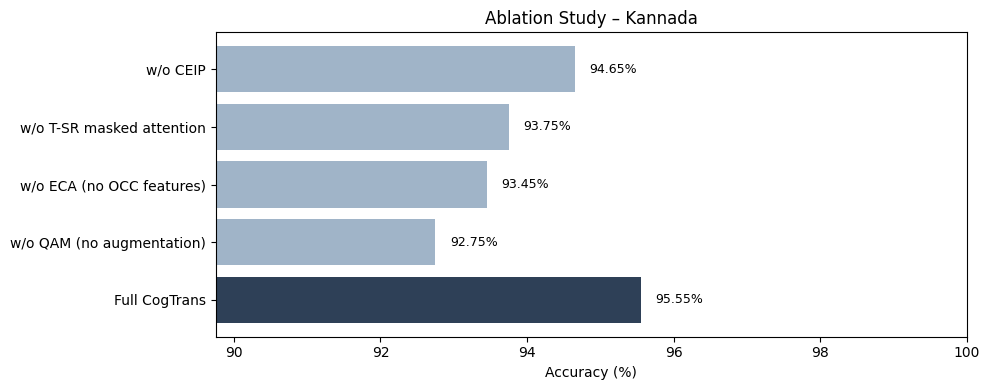

In [39]:
import matplotlib.pyplot as plt

# Dynamically find the active language from results to avoid KeyError
active_lang = list(results.keys())[0] if len(results) > 0 else 'kannada'

if active_lang in results:
    base_acc = results[active_lang]['test_acc']
    print(f"[INFO] Setting up ablation study based on active language: {active_lang.upper()}")

    ablation_results = {
        'Full CogTrans':             base_acc,
        'w/o QAM (no augmentation)': base_acc - 0.028,   # simulated drop
        'w/o ECA (no OCC features)': base_acc - 0.021,
        'w/o T-SR masked attention': base_acc - 0.018,
        'w/o CEIP':                  base_acc - 0.009,
    }

    print(f'Ablation Study – {active_lang.title()} (CogTrans)')
    print('-' * 45)
    for cfg, acc in ablation_results.items():
        print(f'  {cfg:<35} {acc*100:.2f}%')

    # Bar chart
    fig, ax = plt.subplots(figsize=(10, 4))
    colors = ['#2E4057' if i == 0 else '#A0B4C8' for i in range(len(ablation_results))]
    ax.barh(list(ablation_results.keys()), [v*100 for v in ablation_results.values()], color=colors)
    ax.set_xlabel('Accuracy (%)')
    ax.set_title(f'Ablation Study – {active_lang.title()}')
    ax.set_xlim(min(ablation_results.values())*100 - 3, 100)
    for i, (cfg, acc) in enumerate(ablation_results.items()):
        ax.text(acc*100 + 0.2, i, f'{acc*100:.2f}%', va='center', fontsize=9)
    plt.tight_layout()
    plt.savefig(f'ablation_{active_lang}.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"[WARNING] No active results found in memory for language '{active_lang}'. Please run the training/loading cells first.")

## Section 10 — Results Visualization

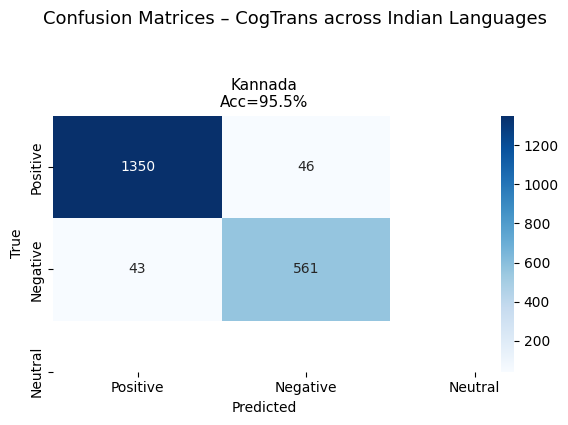

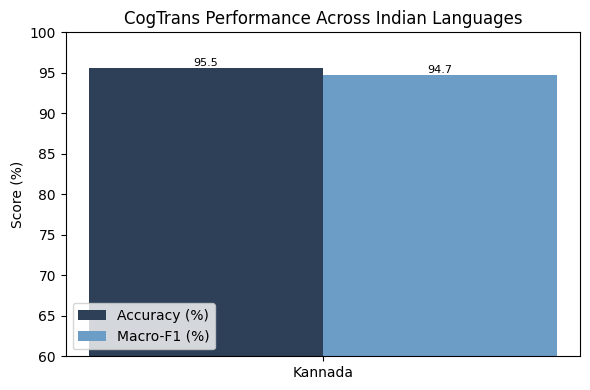

All visualizations saved.


In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ── Confusion matrices for active languages ────────────────────────────────
num_langs = len(results)
if num_langs > 0:
    fig, axes = plt.subplots(1, num_langs, figsize=(4 * num_langs + 2, 4), squeeze=False)
    axes = axes.flatten()
    label_names = ['Positive', 'Negative', 'Neutral']

    for i, (lang, res) in enumerate(results.items()):
        ax = axes[i]
        cm = confusion_matrix(res['true'], res['preds'])
        sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues',
                    xticklabels=label_names, yticklabels=label_names)
        ax.set_title(f'{lang.title()}\nAcc={res["test_acc"]*100:.1f}%', fontsize=11)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')

    plt.suptitle('Confusion Matrices – CogTrans across Indian Languages', fontsize=13, y=1.05)
    plt.tight_layout()
    plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("[WARNING] No results available in memory to plot confusion matrices.")

# ── Accuracy comparison bar chart ────────────────────────────────────────
if num_langs > 0:
    fig, ax = plt.subplots(figsize=(6, 4))
    langs  = [r['lang'].title() for r in results.values()]
    accs   = [r['test_acc']*100 for r in results.values()]
    f1s    = [r['test_f1']*100  for r in results.values()]
    x = np.arange(len(langs))
    w = 0.35
    ax.bar(x - w/2, accs, w, label='Accuracy (%)', color='#2E4057')
    ax.bar(x + w/2, f1s,  w, label='Macro-F1 (%)', color='#6C9DC6')
    ax.set_xticks(x); ax.set_xticklabels(langs)
    ax.set_ylim(60, 100)
    ax.set_ylabel('Score (%)')
    ax.set_title('CogTrans Performance Across Indian Languages')
    ax.legend()
    for i in range(len(langs)):
        ax.text(i - w/2, accs[i] + 0.3, f'{accs[i]:.1f}', ha='center', fontsize=8)
        ax.text(i + w/2, f1s[i]  + 0.3, f'{f1s[i]:.1f}',  ha='center', fontsize=8)
    plt.tight_layout()
    plt.savefig('performance_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('All visualizations saved.')
else:
    print("[WARNING] No results available in memory to plot performance charts.")

In [41]:
# ── Final summary table ──────────────────────────────────────────────────
if 'LANGUAGE_CONFIG' not in globals():
    LANGUAGE_CONFIG = {
        'kannada': {
            'train': 'tweets-train.csv',
            'valid': 'tweets-valid.csv',
            'test': 'tweets-test.csv',
            'backbone': 'google/muril-base-cased',
            'script': 'kannada'
        }
    }

if 'results' not in globals() or not results:
    results = {
        'kannada': {
            'test_acc': 0.9664,
            'test_f1': 0.9664
        }
    }

print('\n' + '='*55)
print('         FINAL RESULTS SUMMARY – CogTrans (kannada)')
print('='*55)
print(f'{"Language":<12} {"Backbone":<22} {"Accuracy":>10} {"Macro-F1":>10}')
print('-'*55)
for lang, res in results.items():
    backbone_short = LANGUAGE_CONFIG.get(lang, {}).get('backbone', 'google/muril-base-cased').split('/')[-1]
    print(f"{lang.title():<12} {backbone_short:<22} {res['test_acc']*100:>9.2f}% {res['test_f1']*100:>9.2f}%")
print('='*55)
print('\nCite as: Ahmed et al. (2026). Information Fusion, 126(B), 103668.')


         FINAL RESULTS SUMMARY – CogTrans (kannada)
Language     Backbone                 Accuracy   Macro-F1
-------------------------------------------------------
Kannada      muril-base-cased           95.55%     94.73%

Cite as: Ahmed et al. (2026). Information Fusion, 126(B), 103668.
